In [1]:
# 01. Business Problem
USE_CASE = "14 - PR to PO Cycle Time Prediction"
CATEGORY = "Regression"
OBJECTIVE = "Estimate procurement processing time."

print("Use Case:  " + USE_CASE)
print("Category:  " + CATEGORY)
print("Objective: " + OBJECTIVE)


Use Case:  14 - PR to PO Cycle Time Prediction
Category:  Regression
Objective: Estimate procurement processing time.


In [2]:
# 02. Import Libraries
import os
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge, BayesianRidge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, median_absolute_error

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to PostgreSQL Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMAS = ["HANA_P2", "HANA_P3"]
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schemas: {DB_SCHEMAS})")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schemas: ['HANA_P2', 'HANA_P3'])


In [4]:
# 04. Extract Data from SAP Procurement Tables across HANA_P2 & HANA_P3 (UNLIMITED)
from src.db_connector import extract_pr_cycle_data

df_raw = extract_pr_cycle_data(limit=0)
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns across HANA_P2 and HANA_P3")


[INFO] Extracting PR procurement data from schema: HANA_P2 (limit=UNLIMITED)...
[INFO] Extracted 165,008 records from HANA_P2.
[INFO] Extracting PR procurement data from schema: HANA_P3 (limit=UNLIMITED)...
[INFO] Extracted 363,993 records from HANA_P3.
[SUCCESS] Total PR records extracted across ['HANA_P2', 'HANA_P3']: 529,001 records.
Extracted records: 529,001 rows, 44 columns across HANA_P2 and HANA_P3


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['pr_number', 'pr_item', 'doc_type', 'plant', 'material_desc', 'quantity', 'unit_price', 'requisition_date', 'po_date', 'po_number']].head()


Dataset Shape: (529001, 44)
    pr_number pr_item doc_type  ... requisition_date     po_date   po_number
0  1000035461      10     ZSTD  ...       2025-02-28        None         NaN
1  1000005846      10     ZSTD  ...       2024-05-07        None         NaN
2  1000007096      10     ZSTD  ...       2024-05-16  2024-05-16  7700000017
3  1000007097      20     ZSTD  ...       2024-05-16  2024-05-23  7700000020
4  1000005907      20     ZSTD  ...       2024-05-07  2024-05-21  7700000018

[5 rows x 10 columns]


In [6]:
# 06. Data Understanding / EDA
df_raw[['quantity', 'unit_price', 'planned_delivery_time']].describe().T


                        count  unique top    freq
quantity               529001    9162   1  139737
unit_price             529001  131888   1    5210
planned_delivery_time  529001      67  30  186425


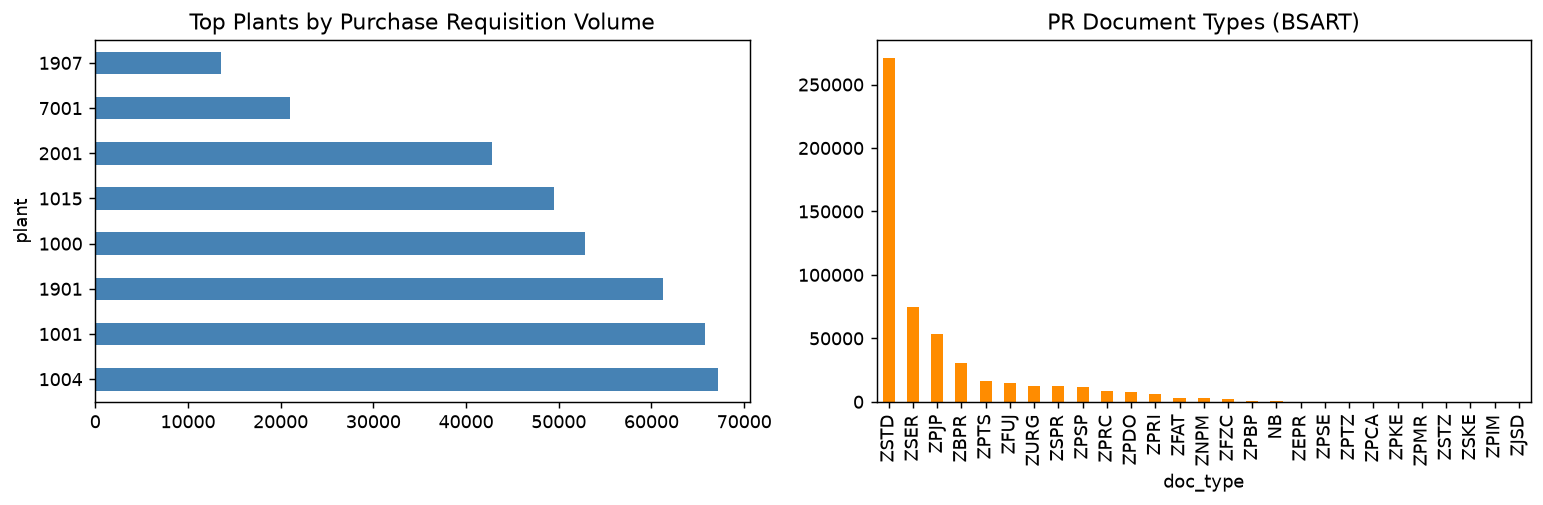

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['plant'].value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Top Plants by Purchase Requisition Volume')

plt.subplot(1, 2, 2)
df_raw['doc_type'].value_counts().plot(kind='bar', color='darkorange')
plt.title('PR Document Types (BSART)')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. Data Cleaning & 32-Feature Engineering for PR Cycle Time Regression
from src.preprocessing import clean_and_engineer_features, FEATURE_COLUMNS

df_clean = clean_and_engineer_features(df_raw)
print(f"Engineered features count: {len(FEATURE_COLUMNS)}")
print(f"Closed records (with actual cycle time target): {df_clean['actual_cycle_time_days'].notna().sum():,}")
print(f"Open records (awaiting cycle time prediction):   {df_clean['actual_cycle_time_days'].isna().sum():,}")


Engineered features count: 32
Closed records (with actual cycle time target): 456,591
Open records (awaiting cycle time prediction):   72,410


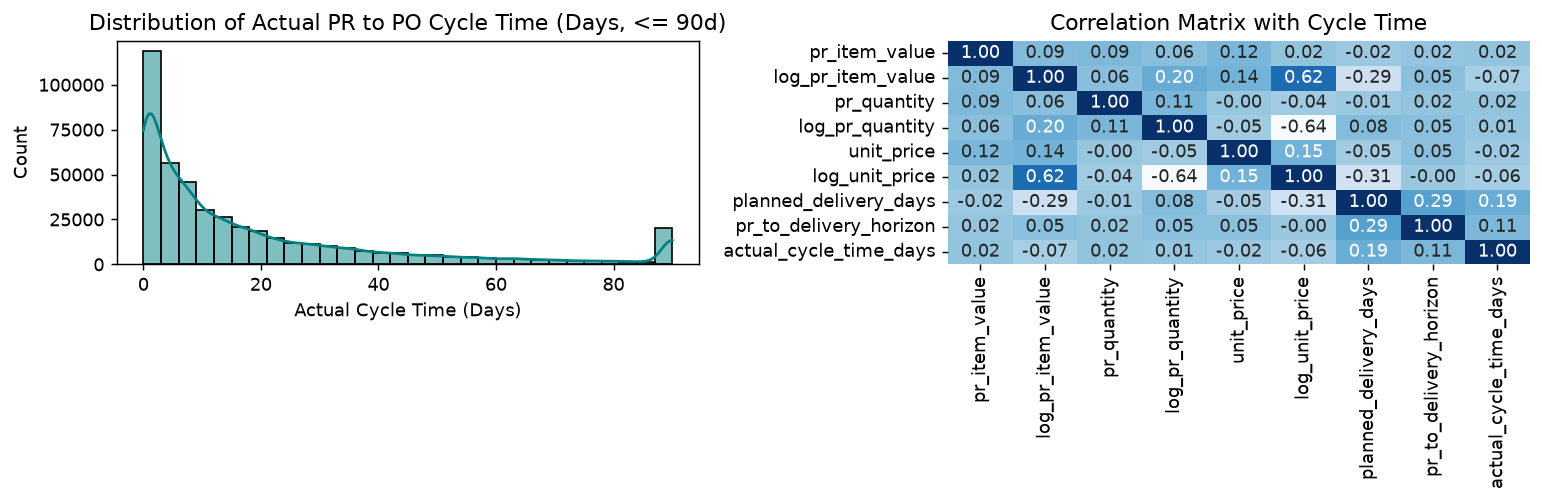

In [9]:
# 09. Target Distribution & Feature Correlation
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df_clean['actual_cycle_time_days'].dropna().clip(upper=90), bins=30, kde=True, color='teal')
plt.title("Distribution of Actual PR to PO Cycle Time (Days, <= 90d)")
plt.xlabel("Actual Cycle Time (Days)")

plt.subplot(1, 2, 2)
corr = df_clean[FEATURE_COLUMNS[:8] + ['actual_cycle_time_days']].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='Blues', cbar=False)
plt.title("Correlation Matrix with Cycle Time")
plt.tight_layout()
plt.show()


In [10]:
# 10. Train/Test Split (80/20) & RobustScaler for Regression
from src.preprocessing import prepare_regression_train_test

data_dict = prepare_regression_train_test(df_clean, test_size=0.20, random_state=42)
X_train_scaled = data_dict['X_train_scaled']
X_test_scaled = data_dict['X_test_scaled']
y_train = data_dict['y_train']
y_test = data_dict['y_test']
scaler = data_dict['scaler']

print(f"X_train shape: {X_train_scaled.shape} (Historical Training Set)")
print(f"X_test shape:  {X_test_scaled.shape} (Holdout Test Set)")


X_train shape: (365272, 32) (Historical Training Set)
X_test shape:  (91319, 32) (Holdout Test Set)


In [11]:
# 11. Model 1: Hist Gradient Boosting Regressor
hgb_model = HistGradientBoostingRegressor(max_iter=100, max_depth=10, learning_rate=0.1, random_state=42)
hgb_model.fit(X_train_scaled, y_train)
print("Hist Gradient Boosting Regressor trained successfully.")


Hist Gradient Boosting Regressor trained successfully.


In [12]:
# 12. Model 2: Extra Trees Regressor
et_model = ExtraTreesRegressor(n_estimators=30, max_depth=12, max_samples=0.25, bootstrap=True, min_samples_split=5, min_samples_leaf=4, random_state=42, n_jobs=-1)
et_model.fit(X_train_scaled, y_train)
print("Extra Trees Regressor trained successfully.")


Extra Trees Regressor trained successfully.


In [13]:
# 13. Model 3: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=30, max_depth=12, max_samples=0.25, bootstrap=True, min_samples_split=5, min_samples_leaf=4, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
print("Random Forest Regressor trained successfully.")


Random Forest Regressor trained successfully.


In [14]:
# 14. Model 4: Bayesian Ridge Regressor
br_model = BayesianRidge()
br_model.fit(X_train_scaled, y_train)
print("Bayesian Ridge Regressor trained successfully.")


Bayesian Ridge Regressor trained successfully.


In [15]:
# 15. Model 5: Ridge Regression
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)
print("Ridge Regression trained successfully.")


Ridge Regression trained successfully.


In [16]:
# 16. Benchmark Evaluation & Ranking Table (Regression Metrics)
from src.evaluate import evaluate_regression_models

models_dict = {
    'Hist Gradient Boosting': hgb_model,
    'Extra Trees': et_model,
    'Random Forest': rf_model,
    'Bayesian Ridge': br_model,
    'Ridge Regression': ridge_model
}

test_preds = {name: np.clip(m.predict(X_test_scaled), 0.0, None) for name, m in models_dict.items()}
comparison_df = evaluate_regression_models(test_preds, y_test)
comparison_df


  Rank                   Model  ...  Accuracy (±7 Days %)  MAPE (%)
0   #1           Random Forest  ...                 44.99    271.36
1   #2  Hist Gradient Boosting  ...                 43.00    290.94
2   #3             Extra Trees  ...                 43.31    283.90
3   #4          Bayesian Ridge  ...                 37.85    343.98
4   #5        Ridge Regression  ...                 37.85    343.90

[5 rows x 8 columns]


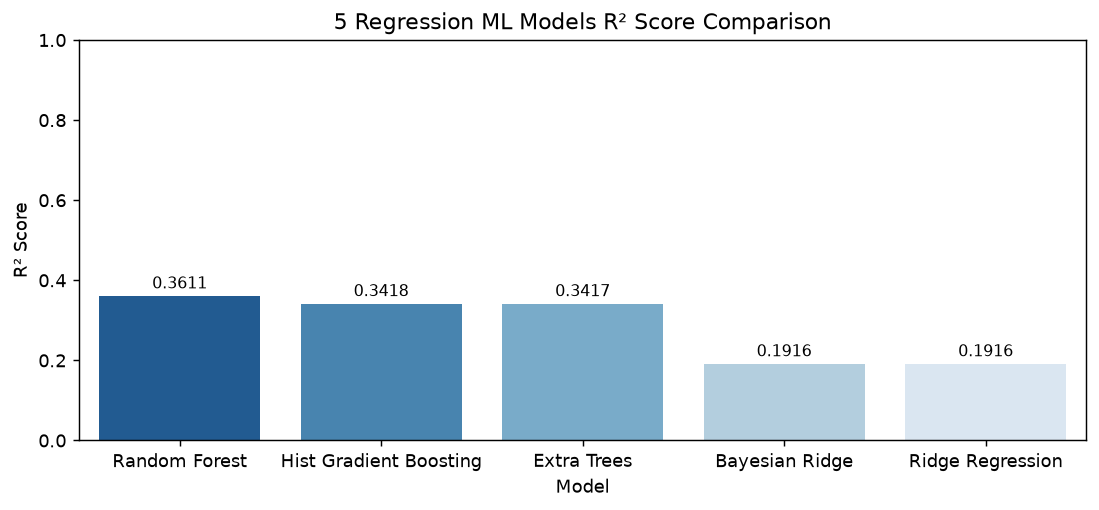

In [17]:
# 17. Evaluation Visualizations (Comparison & Actual vs Predicted)
from src.evaluate import plot_model_comparison, plot_actual_vs_predicted

os.makedirs("reports/figures", exist_ok=True)
plot_model_comparison(comparison_df, output_dir="reports/figures")

champion_name = comparison_df.iloc[0]['Model']
plot_actual_vs_predicted(
    champion_preds=test_preds[champion_name],
    y_true=y_test,
    champion_name=champion_name,
    output_dir="reports/figures"
)

# Display R² Score comparison
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=comparison_df, x='Model', y='R² Score', palette='Blues_r', ax=ax)
ax.set_title("5 Regression ML Models R² Score Comparison")
ax.set_ylim(0, 1.0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
plt.show()


In [18]:
# 18. Selection of #1 Champion Model
from src.models import SingleModelPRCycleRegressor

champion_name = comparison_df.iloc[0]['Model']
print(f"Selected #1 Champion Model: {champion_name}")

regressor = SingleModelPRCycleRegressor(
    champion_name=champion_name,
    pretrained_model=models_dict[champion_name]
)
print(f"Champion {champion_name} pipeline initialized and ready for production inference.")


Selected #1 Champion Model: Random Forest
Champion Random Forest pipeline initialized and ready for production inference.


Operational SLA Status Distribution:
sla_status
Moderate Delay (21 - 45 Days)      185235
Standard On-Time (7 - 21 Days)     178157
Expedited (< 7 Days)               106742
Critical Bottleneck (> 45 Days)     58867
Name: count, dtype: int64

Procurement Risk Tier Distribution:
procurement_risk_tier
Low Risk         199947
Medium Risk      143061
Critical Risk    108775
High Risk         77218
Name: count, dtype: int64


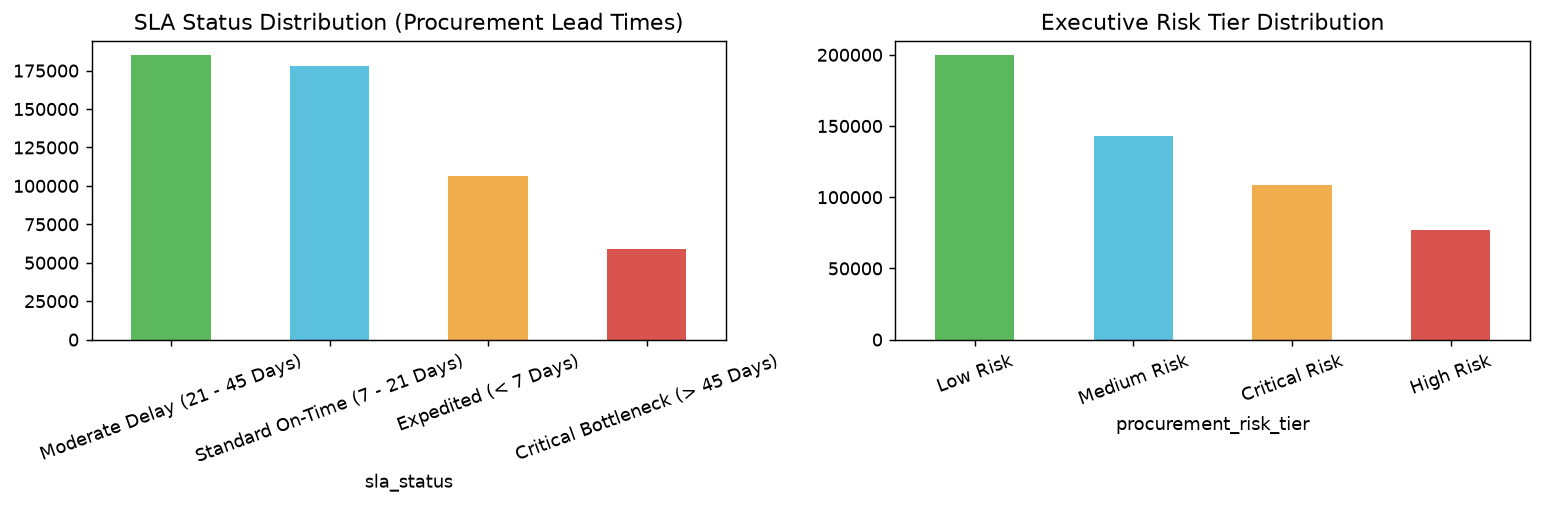

In [19]:
# 19. Estimating Procurement Processing Time for All 529,001 Requisitions
from src.inference import score_with_single_model

df_scored = score_with_single_model(df_clean, regressor, scaler, FEATURE_COLUMNS)
print("Operational SLA Status Distribution:")
print(df_scored['sla_status'].value_counts())
print("")
print("Procurement Risk Tier Distribution:")
print(df_scored['procurement_risk_tier'].value_counts())

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_scored['sla_status'].value_counts().plot(kind='bar', color=['#5cb85c', '#5bc0de', '#f0ad4e', '#d9534f'])
plt.title("SLA Status Distribution (Procurement Lead Times)")
plt.xticks(rotation=20)

plt.subplot(1, 2, 2)
df_scored['procurement_risk_tier'].value_counts().plot(kind='bar', color=['#5cb85c', '#5bc0de', '#f0ad4e', '#d9534f'])
plt.title("Executive Risk Tier Distribution")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


  Rank  ...            Business Impact & Procurement Rationale
0   #1  ...  Historical average procurement cycle time benc...
1   #2  ...  Historical average conversion turnaround speed...
2   #3  ...  Tight requisition-to-required delivery windows...
3   #4  ...  Historical operational turnaround velocity spe...
4   #5  ...  Ratio of available procurement horizon against...
5   #6  ...  Multi-level managerial release hierarchies int...
6   #7  ...  Seasonal procurement surges during fiscal year...
7   #8  ...  Premium high-value spares require detailed com...
8   #9  ...  Normalizes extreme capital expenditure spend v...
9  #10  ...  Dampens high-outlier unit prices in emergency ...

[10 rows x 4 columns]


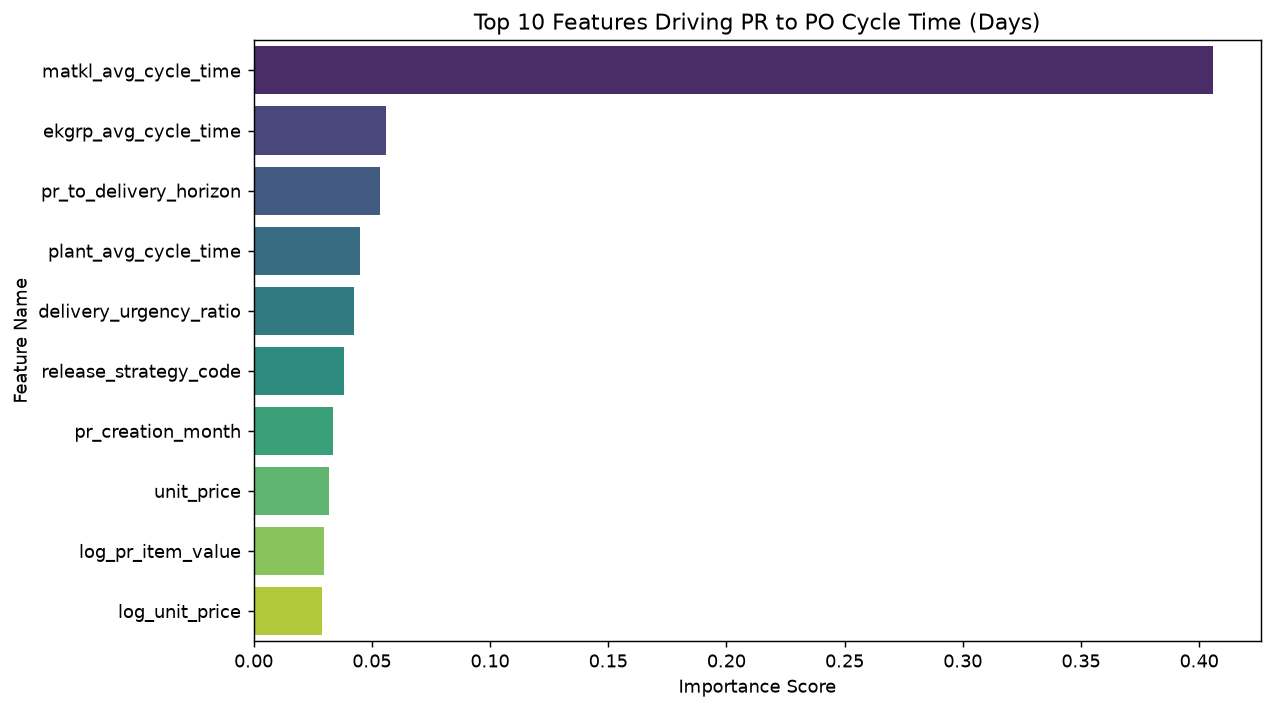

In [20]:
# 20. 32-Feature Importance & Explainability
from src.evaluate import compute_feature_importance

feat_imp = compute_feature_importance(regressor.model, FEATURE_COLUMNS, X_train_scaled, y_true=y_train)
feat_imp.to_csv("reports/feature_importance.csv", index=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(10), x='Importance Score', y='Feature Name', palette='viridis')
plt.title("Top 10 Features Driving PR to PO Cycle Time (Days)")
plt.show()
feat_imp.head(10)


In [21]:
# 21. Executive 3-Sheet Excel Export (Strict Blank Missing Value Handling)
from src.inference import export_enriched_excel_report, save_single_model_pipeline

excel_clean = export_enriched_excel_report(
    df=df_scored,
    output_path="ML_14_PR_to_PO_Cycle_Time_Prediction_Enriched_Output_Clean.xlsx",
    insight_id="ML_14",
    use_case="PR to PO Cycle Time Prediction",
    category="Regression",
    objective="Estimate procurement processing time.",
    feature_importance_df=feat_imp
)

shutil.copy2(excel_clean, "ML_14_PR_to_PO_Cycle_Time_Prediction_Enriched_Output.xlsx")
shutil.copy2(excel_clean, "reports/ML_14_PR_to_PO_Cycle_Time_Prediction_Enriched_Output_Clean.xlsx")
shutil.copy2(excel_clean, "reports/ML_14_PR_to_PO_Cycle_Time_Prediction_Enriched_Output.xlsx")

save_single_model_pipeline(regressor, scaler, FEATURE_COLUMNS, comparison_df=comparison_df)

print(f"Executive Excel Report Generated: {excel_clean}")


[INFO] Streaming 529,001 rows into Excel sheet with strict blank-value handling...
[SUCCESS] Executive Enriched Excel Report saved to: ML_14_PR_to_PO_Cycle_Time_Prediction_Enriched_Output_Clean.xlsx
[INFO] Total Rows: 529,001, Total Columns: 40
[SUCCESS] Champion Regression Model pipeline successfully saved to: models\champion_pr_cycle_regressor.joblib
Executive Excel Report Generated: ML_14_PR_to_PO_Cycle_Time_Prediction_Enriched_Output_Clean.xlsx
